In [1]:
import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import expon
import warnings
import datetime
import scipy.stats as stats
from pygments import highlight
from pygments.lexers import PythonLexer
from pygments.formatters import ImageFormatter



In [2]:
np.random.seed(23)
df = pd.read_csv('database_visits.csv')
pd.set_option('display.float_format', lambda x: '%.3f' % x)
warnings.filterwarnings("ignore")


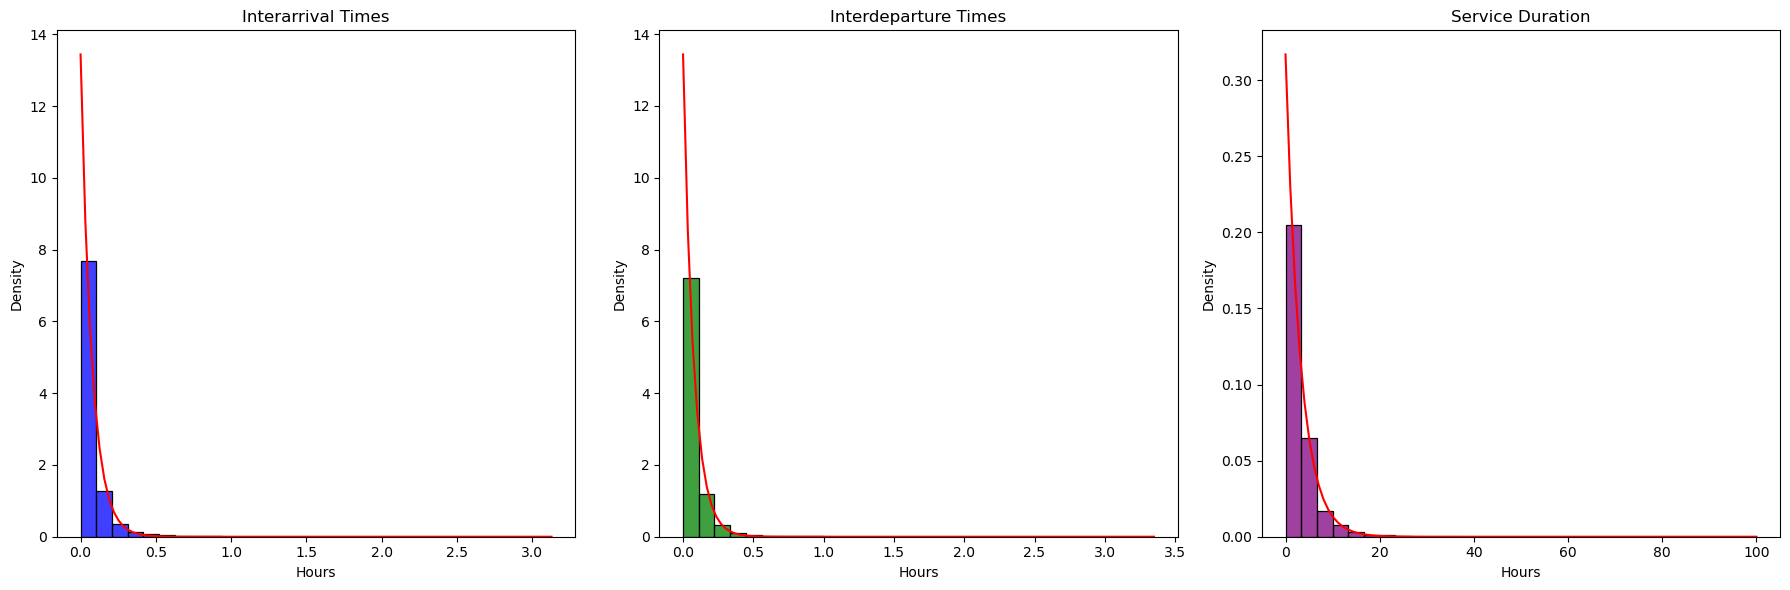

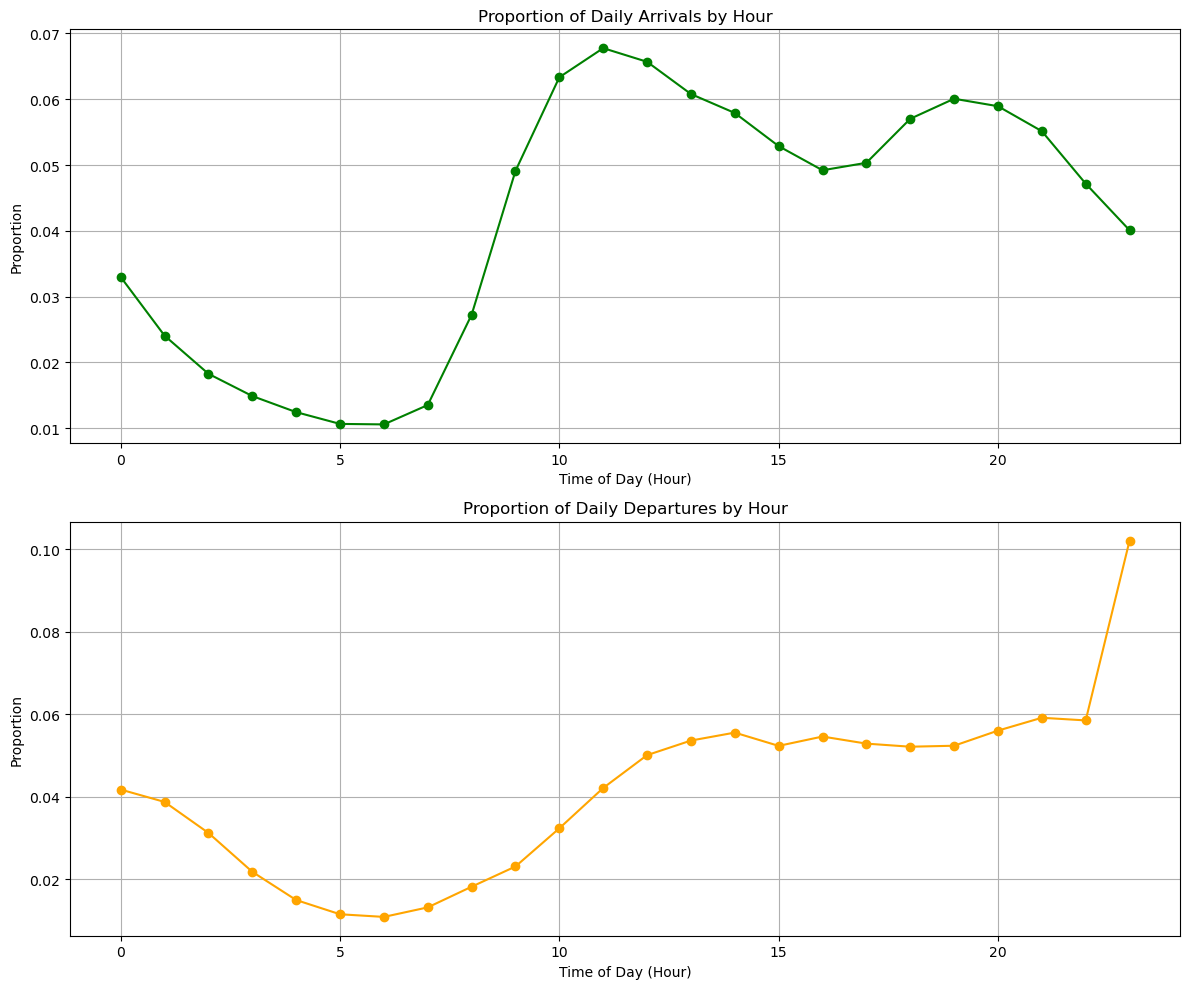

In [3]:

df['entry_time'] = pd.to_datetime(df['entry_time'], unit='s')
df['departure_time'] = df['entry_time'] + pd.to_timedelta(df['ED_dur'], unit='s')
# Convert entry_time and departure_time to datetime
df['departure_time'] = df['entry_time'] + pd.to_timedelta(df['ED_dur'], unit='s')

# Filter and sort data
df = df[df['entry_group'] == 1]
df.sort_values(by='entry_time', inplace=True)

# Calculate interarrival times and interdeparture times
df['interarrival_time'] = df['entry_time'].diff()
df_sorted_by_departure = df.sort_values(by="departure_time", inplace=False)
df['interdeparture_time'] = df_sorted_by_departure['departure_time'].diff()

# Drop rows with NaN values in interarrival or interdeparture times
df = df.dropna(subset=['interarrival_time', 'interdeparture_time'])

# Convert interarrival and interdeparture times to hours
df['interarrival_time_hours'] = df['interarrival_time'] / pd.Timedelta(hours=1)
df['interdeparture_time_hours'] = df['interdeparture_time'] / pd.Timedelta(hours=1)
df['service_duration_hours'] = df['ED_dur'] / 3600

#Cap service durations to 48 hours
df['service_duration_hours'] = df['service_duration_hours'].clip(upper=100)

# Plot histograms with exponential fit for interarrival times, interdeparture times, and service duration
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Interarrival times
sns.histplot(df['interarrival_time_hours'], bins=30, kde=False, stat='density', color='blue', ax=axes[0], label='Interarrival Times')
interarrival_loc, interarrival_scale = expon.fit(df['interarrival_time_hours'])
x = np.linspace(df['interarrival_time_hours'].min(), df['interarrival_time_hours'].max(), 100)
axes[0].plot(x, expon.pdf(x, interarrival_loc, interarrival_scale), 'r-', label='Fitted Exponential')
axes[0].set_title('Interarrival Times')
axes[0].set_xlabel('Hours')
axes[0].set_ylabel('Density')

# Interdeparture times
sns.histplot(df['interdeparture_time_hours'], bins=30, kde=False, stat='density', color='green', ax=axes[1], label='Interdeparture Times')
interdeparture_loc, interdeparture_scale = expon.fit(df['interdeparture_time_hours'])
x = np.linspace(df['interdeparture_time_hours'].min(), df['interdeparture_time_hours'].max(), 100)
axes[1].plot(x, expon.pdf(x, interdeparture_loc, interdeparture_scale), 'r-', label='Fitted Exponential')
axes[1].set_title('Interdeparture Times')
axes[1].set_xlabel('Hours')

# Service duration
sns.histplot(df['service_duration_hours'], bins=30, kde=False, stat='density', color='purple', ax=axes[2], label='Service Duration')
service_loc, service_scale = expon.fit(df['service_duration_hours'])
x = np.linspace(df['service_duration_hours'].min(), df['service_duration_hours'].max(), 100)
axes[2].plot(x, expon.pdf(x, service_loc, service_scale), 'r-', label='Fitted Exponential')
axes[2].set_title('Service Duration')
axes[2].set_xlabel('Hours')

plt.tight_layout()
plt.show()

# Plot proportions for hourly arrivals and departures
# Calculate average interarrival and interdeparture times for each hour of the day
avg_interarrival = df.groupby(df['entry_time'].dt.hour)['interarrival_time_hours'].mean()
avg_interdeparture = df.groupby(df['departure_time'].dt.hour)['interdeparture_time_hours'].mean()

# Calculate average number of arrivals and departures per hour
avg_arrivals_per_hour = 1 / avg_interarrival
avg_departures_per_hour = 1 / avg_interdeparture

# Calculate total daily arrivals and departures
total_daily_arrivals = avg_arrivals_per_hour.sum()
total_daily_departures = avg_departures_per_hour.sum()

# Calculate proportions for hourly arrivals and departures
arrival_proportions = avg_arrivals_per_hour / total_daily_arrivals
departure_proportions = avg_departures_per_hour / total_daily_departures

# Plotting the proportion of daily arrivals and departures by hour as separate subplots
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Arrival proportions
axes[0].plot(arrival_proportions.index, arrival_proportions.values, marker='o', linestyle='-', color='Green', label='Arrival Proportions')
axes[0].set_title('Proportion of Daily Arrivals by Hour')
axes[0].set_xlabel('Time of Day (Hour)')
axes[0].set_ylabel('Proportion')
axes[0].grid(True)

# Departure proportions
axes[1].plot(departure_proportions.index, departure_proportions.values, marker='o', linestyle='-', color='Orange', label='Departure Proportions')
axes[1].set_title('Proportion of Daily Departures by Hour')
axes[1].set_xlabel('Time of Day (Hour)')
axes[1].set_ylabel('Proportion')
axes[1].grid(True)

plt.tight_layout()
plt.show()


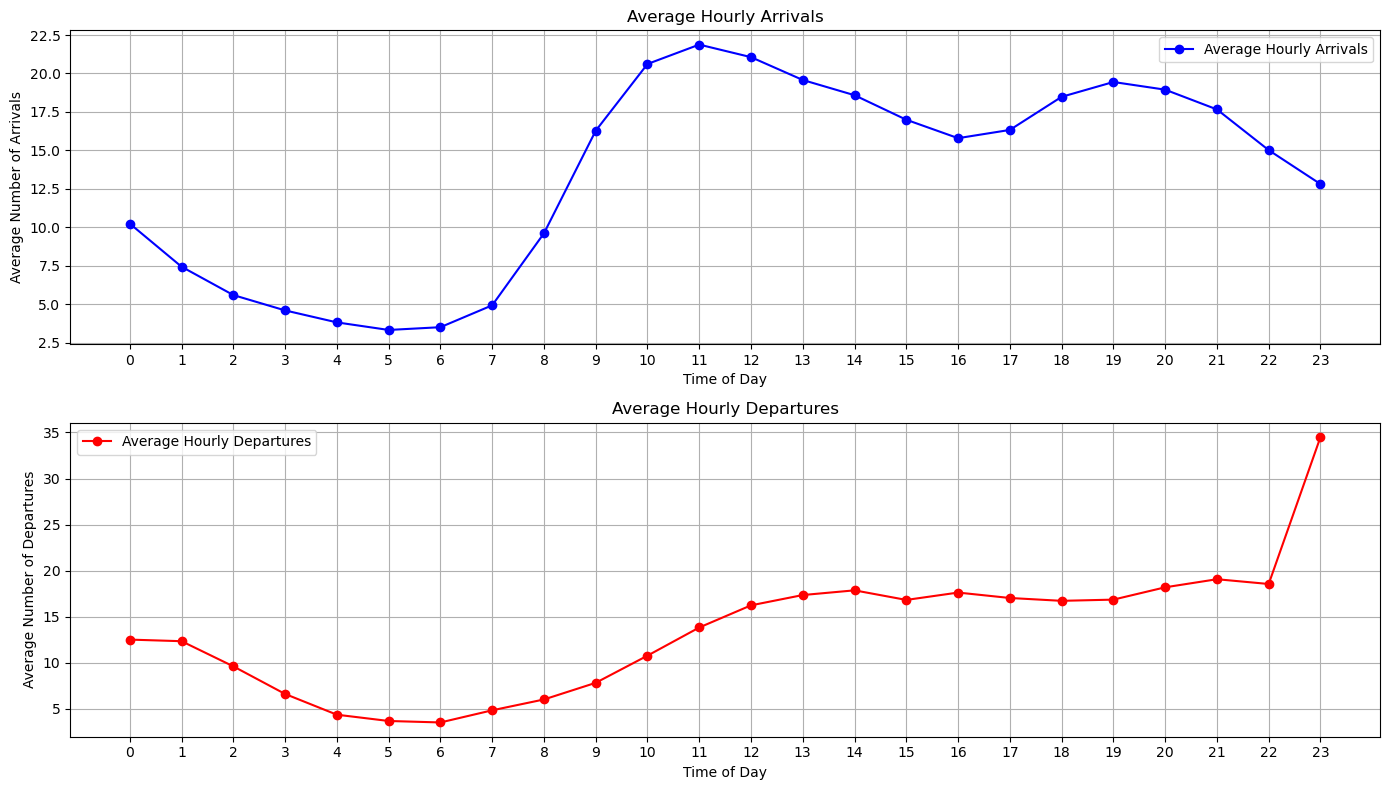

In [4]:


# Extract the date part from entry_time for daily grouping
df['date_only'] = df['entry_time'].dt.date

# Calculate daily hourly counts of arrivals and departures
hourly_arrivals_by_day = df.groupby([df['date_only'], df['entry_time'].dt.hour]).size().unstack(fill_value=0)
hourly_departures_by_day = df.groupby([df['date_only'], df['departure_time'].dt.hour]).size().unstack(fill_value=0)

# Calculate the average hourly arrivals and departures across all days
avg_hourly_arrivals = hourly_arrivals_by_day.mean(axis=0)
avg_hourly_departures = hourly_departures_by_day.mean(axis=0)

# Plotting
plt.figure(figsize=(14, 8))

# Subplot 1: Average Hourly Arrivals
plt.subplot(2, 1, 1)
plt.plot(avg_hourly_arrivals.index, avg_hourly_arrivals.values, marker='o', linestyle='-', color='b', label='Average Hourly Arrivals')
plt.xlabel('Time of Day')
plt.ylabel('Average Number of Arrivals')
plt.title('Average Hourly Arrivals')
plt.xticks(np.arange(0, 24, 1))
plt.grid(True)
plt.legend()

# Subplot 2: Average Hourly Departures
plt.subplot(2, 1, 2)
plt.plot(avg_hourly_departures.index, avg_hourly_departures.values, marker='o', linestyle='-', color='r', label='Average Hourly Departures')
plt.xlabel('Time of Day')
plt.ylabel('Average Number of Departures')
plt.title('Average Hourly Departures')
plt.xticks(np.arange(0, 24, 1))
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()


In [5]:

class AandE:
    def __init__(self, shifts, hourly_arrival, hourly_service):
        self.shifts = shifts
        self.env = simpy.Environment()
        self.patient_log = {}

        self.hourly_data = pd.DataFrame({
            'hour': range(24),
            'arrivals': hourly_arrival,
            "service" : hourly_service
        })

        self.total_doctors = 0
        for k in self.shifts:
            self.total_doctors = max(self.total_doctors, self.shifts[k]["doctors"])
        self.doctors_available = simpy.PriorityResource(self.env, capacity=self.total_doctors)
        self.shift_pattern = self.calculate_shift_pattern()

    def calculate_shift_pattern(self):
        shift_pattern = [0]*24
        for hour in range(24):
            if self.shifts["morning"]["start"] <= hour < self.shifts["morning"]["end"]:
                shift_pattern[hour] = self.shifts["morning"]["doctors"]
            elif  self.shifts["twilight"]["start"] <= hour < self.shifts["twilight"]["end"]:
                shift_pattern[hour] = self.shifts["twilight"]["doctors"]
            else:
                shift_pattern[hour] = self.shifts["night"]["doctors"]
        return shift_pattern

    def calculate_hourly_departures(self):
       return [self.service_rate * d for d in self.doctor_counts]

    def generate_patients(self):
        patient_id = -1
        current_shift = "night" #assume simulation always starts at midnight
        while True:
            hour = int(self.env.now % 24)
            hourly_rate = self.hourly_data.loc[hour, 'arrivals']
            interarrival_time = np.random.exponential(1.0 / hourly_rate)
            yield self.env.timeout(interarrival_time)
            arrival_time = self.env.now
            patient_id += 1

            self.patient_log[patient_id] = {
                'Patient': patient_id,
                'Arrival Time': arrival_time,
                'Waiting Time': np.nan,
                'Service Time': np.nan,
                'Service Duration': np.nan,
                'Departure Time': np.nan,
            }

            res, shift = self.shift_change(hour, current_shift)
            if res is False:
                current_shift = shift
                for _ in range(self.total_doctors - self.shift_pattern[hour]):
                    shift_length = self.shifts[current_shift]['end'] - (self.env.now % 24)
                    self.env.process(self.phantom_patient(shift_length))

            self.env.process(self.patient(patient_id, arrival_time))

    def shift_change(self, hour, current_shift):
        for k in self.shifts:
            if self.shifts[k]["start"] <= hour < self.shifts[k]["end"]:
                if k != current_shift:
                    return False, k
        return True, current_shift



    def patient(self, patient_id, arrival_time):
        with self.doctors_available.request(priority=2) as request:
            yield request
            hour = int(self.env.now % 24)
            hourly_rate = self.hourly_data.loc[hour, 'service']
            treatment_duration = np.random.exponential(1.0 / hourly_rate)
            # treatment_duration = np.random.uniform(20, 30) / 60
            waiting_time = self.env.now - arrival_time
            service_time = self.env.now

            self.patient_log[patient_id]["Waiting Time"] = waiting_time
            self.patient_log[patient_id]["Service Time"] = service_time

            yield self.env.timeout(treatment_duration)

            self.patient_log[patient_id]["Service Duration"] = treatment_duration
            departure_time = self.env.now
            self.patient_log[patient_id]["Departure Time"] = departure_time

    def phantom_patient(self, shift_length):
        with self.doctors_available.request(priority=1) as request:
            yield request
            treatment_duration = shift_length
            yield self.env.timeout(treatment_duration)

    def run_simulation(self, simulation_time=1440):
        self.env.process(self.generate_patients())
        self.env.run(until=simulation_time)

    def save_log_to_csv(self, filename='patient_log.csv'):
        df = pd.DataFrame.from_dict(self.patient_log, orient='index')
        df['Day'] = (df['Arrival Time'] // 24).astype(int)
        df['Arrival Time'] = (df['Arrival Time'] * 60) * 1
        df["Waiting Time"] = (df["Waiting Time"] * 60) * 1
        df['Service Time'] = (df['Service Time'] * 60) * 1
        df['Departure Time'] = (df['Departure Time'] * 60) * 1
        df['Service Duration'] = (df['Service Duration'] * 60) * 1
        df.reset_index(drop=True, inplace=True)

        # Convert times to HH:MM:SS format, handling NaN values
        df['Arrival Time'] = df['Arrival Time'].apply(lambda x: (datetime.datetime.min + datetime.timedelta(minutes=x)).strftime('%H:%M:%S') if not pd.isna(x) else 'N/A')
        df['Service Time'] = df['Service Time'].apply(lambda x: (datetime.datetime.min + datetime.timedelta(minutes=x)).strftime('%H:%M:%S') if not pd.isna(x) else 'N/A')
        df['Departure Time'] = df['Departure Time'].apply(lambda x: (datetime.datetime.min + datetime.timedelta(minutes=x)).strftime('%H:%M:%S') if not pd.isna(x) else 'N/A')

        # Combine Day and Arrival Time
        df['Day and Arrival Time'] = df.apply(lambda row: f'Day {row["Day"]} {row["Arrival Time"]}', axis=1)
        df = df[['Patient', 'Day and Arrival Time', 'Waiting Time', 'Service Time', 'Service Duration', 'Departure Time']]
        df.to_csv(filename, index=False)
        print(f"Simulation complete. Patient log saved to '{filename}'.")

    def doctors_per_hour(self):
        hours = range(24)
        doctor_counts = self.calculate_shift_pattern()
        print("\nCount of Doctors arrival for each hour:")
        return doctor_counts
        print(doctor_counts)

    # Plot a histogram with exponential distribution line
    def plot_hist(self, data, title, xlabel, color='blue'):
        plt.figure(figsize=(10, 6))
        plt.hist(data, bins=30, density=True, alpha=0.6, color=color, label=title)

        lambda_param = 1 / data.mean()
        x = np.linspace(0, data.max(), 100)
        y = lambda_param * np.exp(-lambda_param * x)
        title = f"{title}, rate = {lambda_param:.4f}"
        plt.plot(x, y, 'r-', lw=2, label='Exponential Fit')

        plt.xlabel(xlabel)
        plt.ylabel('Density')
        plt.title(title)
        plt.legend()
        plt.show()



    def plot_queue(self, time, queue_length, title, xlabel, color="black"):
        plt.figure(figsize=(10, 6))
        plt.stairs(queue_length[1:], time, baseline=None, color=color)

        plt.xlabel(xlabel)
        plt.ylabel('Queue Length')
        plt.title(title)
        plt.show()

    def visualize(self, simulation_time=1440):
        patient_df = pd.DataFrame.from_dict(self.patient_log, orient="index")
        time_bins = np.arange(0, simulation_time + 1, 1)
        
        # Create x_labels for every hour
        x_labels = [f"{int(tick)}:00" for tick in time_bins[:-1]]
        
        # Select only every 5th label for the xticks
        xtick_labels = [x_labels[i] if i % 5 == 0 else '' for i in range(len(x_labels))]
    
        def plot_chart(y_data, y_label, title, color='blue'):
            plt.figure(figsize=(10, 6))
            plt.plot(x_labels, y_data, label=title, color=color)
            plt.xlabel('Time (hours)')
            plt.ylabel(y_label)
            plt.title(title)
            plt.grid(True)
            plt.legend()
            
            # Set xticks to every 5th label
            plt.xticks(np.arange(0, len(x_labels), 5), xtick_labels[::5], rotation=45)
            
            plt.show()
    
        # Grouping data for plotting
        arrivals_per_hour = combined_df.groupby(pd.cut(combined_df['Arrival Time'], time_bins)).size()
        waiting_times = combined_df.groupby(pd.cut(combined_df['Arrival Time'], time_bins))['Waiting Time'].mean()
        service_durations = combined_df.groupby(pd.cut(combined_df['Arrival Time'], time_bins))['Service Duration'].mean()
        departures_per_hour = combined_df.groupby(pd.cut(combined_df['Departure Time'], time_bins)).size()

        plot_chart(arrivals_per_hour, 'Number of Patients', 'Number of Patients Arriving per Hour')
        plot_chart(waiting_times, 'Waiting Time (minutes)', 'Average Waiting Time per Hour', color='orange')
        plot_chart(service_durations, 'Service Duration (minutes)', 'Average Service Duration per Hour', color='green')
        plot_chart(departures_per_hour, 'Number of Patients', 'Number of Patients Leaving per Hour', color='red')

        # Histograms with exponential lines for interarrival, interdeparture times, and service duration
        interarrival_times = combined_df['Arrival Time'].dropna().diff()
        interdeparture_times = combined_df['Departure Time'].dropna().sort_values(ascending=True, inplace=False).diff()
        service_durations = combined_df['Service Duration'].dropna()

        def plot_hist(data, title, xlabel, color='blue'):
            plt.figure(figsize=(10, 6))
            plt.hist(data, bins=30, density=True, alpha=0.6, color=color, label=title)

            lambda_param = 1 / data.mean()
            x = np.linspace(0, data.max(), 100)
            y = lambda_param * np.exp(-lambda_param * x)
            title = f"{title}, rate = {lambda_param:.4f}"
            plt.plot(x, y, 'r-', lw=2, label='Exponential Fit')

            plt.xlabel(xlabel)
            plt.ylabel('Density')
            plt.title(title)
            plt.legend()
            plt.show()

        plot_hist(interarrival_times, 'Interarrival Time Distribution', 'Interarrival Time (minutes)', color='green')
        plot_hist(interdeparture_times, 'Interdeparture Time Distribution', 'Interdeparture Time (minutes)', color='blue')
        plot_hist(service_durations, 'Service Duration Distribution', 'Service Duration (minutes)', color='magenta')

        queue_length = np.zeros_like(time_bins)

        for idx, t in enumerate(time_bins):
            num_arrivals = sum(combined_df["Arrival Time"] < t)
            num_departures = sum(combined_df["Departure Time"] < t)
            queue_length[idx] = num_arrivals - num_departures

        plt.figure(figsize=(10, 6))
        plt.stairs(queue_length[1:], time_bins, baseline=None, color="black")
        plt.xlabel("Time (minutes)")
        plt.ylabel("Queue Length")
        plt.title("Queue Length Over Time")
        plt.show()


    def visualize(self, simulation_time=1440):
        patient_df = pd.DataFrame.from_dict(self.patient_log, orient="index")
        time_bins = np.arange(0, simulation_time + 1, 1)
        
        # Create x_labels for every hour
        x_labels = [f"{int(tick)}:00" for tick in time_bins[:-1]]
        
        # Create the positions for xticks (every 5th hour)
        xtick_positions = np.arange(0, len(x_labels), 5)
        xtick_labels = [x_labels[i] for i in xtick_positions]
    
        def plot_chart(y_data, y_label, title, color='blue'):
            plt.figure(figsize=(10, 6))
            plt.plot(range(len(x_labels)), y_data, label=title, color=color)
            plt.xlabel('Time (hours)')
            plt.ylabel(y_label)
            plt.title(title)
            plt.grid(True)
            plt.legend()
            
            # Set xticks every 5 hours
            plt.xticks(xtick_positions, xtick_labels, rotation=45)
            
            plt.show()

        # Calculate and plot statistics
        arrivals_per_hour = patient_df.groupby(pd.cut(patient_df['Arrival Time'], time_bins)).size()
        waiting_times = patient_df.groupby(pd.cut(patient_df['Arrival Time'], time_bins))['Waiting Time'].mean()
        service_durations = patient_df.groupby(pd.cut(patient_df['Arrival Time'], time_bins))['Service Duration'].mean()
        departures_per_hour = patient_df.groupby(pd.cut(patient_df['Departure Time'], time_bins)).size()

        plot_chart(arrivals_per_hour, 'Number of Patients', 'Number of Patients Arriving per Hour')
        plot_chart(waiting_times, 'Waiting Time (hour)', 'Average Waiting Time per Hour', color='orange')
        plot_chart(service_durations, 'Service Duration (minutes)', 'Average Service Duration per Hour', color='green')
        plot_chart(departures_per_hour, 'Number of Patients', 'Number of Patients Leaving per Hour', color='red')
        # Histograms with exponential lines for interarrival, interdeparture times, and service duration
        interarrival_times = patient_df['Arrival Time'].dropna().diff()
        interdeparture_times = patient_df['Departure Time'].dropna().sort_values(ascending=True, inplace=False).diff()
        service_durations = patient_df['Service Duration'].dropna()

        self.plot_hist(interarrival_times, 'Interarrival Time Distribution', 'Interarrival Time (hours)', color='green')
        self.plot_hist(interdeparture_times, 'Interdeparture Time Distribution', 'Interdeparture Time (hours)', color='blue')
        self.plot_hist(service_durations, 'Service Duration Distribution', 'Service Duration (hours)', color='magenta')

        queue_length = np.zeros_like(time_bins)

        for idx, t in enumerate(time_bins):
            num_arrivals = sum(patient_df["Arrival Time"] < t)
            num_departures = sum(patient_df["Departure Time"] < t)
            queue_length[idx] = num_arrivals - num_departures

        self.plot_queue(time_bins, queue_length, "Queue Length", "Time (hour)")

        summary_stats = patient_df.describe()
        print(summary_stats)

# New Section

from google.colab import drive
drive.mount('/content/drive')

CPU times: total: 0 ns
Wall time: 0 ns
[26.54717779767861, 19.37030847073944, 14.704358715536223, 11.982666547661083, 10.013953062870936, 8.573705325949282, 8.512859234802901, 10.88490904745385, 21.92988589096984, 39.53291278986121, 50.992329107300854, 54.55420887713617, 52.882910588330915, 48.93893953080438, 46.621643694911505, 42.56370842491401, 39.61040012830108, 40.52442480562158, 45.9088538447074, 48.363218354129074, 47.44885308748845, 44.39381777886663, 37.97099475252077, 32.27296014144372]
[33.63416384432335, 31.223082381209966, 25.174993084761315, 17.588265592161058, 12.086333356066895, 9.310641407743558, 8.795005998065065, 10.65274981690871, 14.685042316299556, 18.6310998525145, 26.079932917248883, 33.9451715637827, 40.35097105999936, 43.19369814871587, 44.746086225447925, 42.1580967256956, 43.97862994346302, 42.597129828476646, 41.994299356111306, 42.18509929076766, 45.13435975344863, 47.641008063444254, 47.12375927013629, 82.19038020320798]
[3.0576512585748503, 2.83846203465

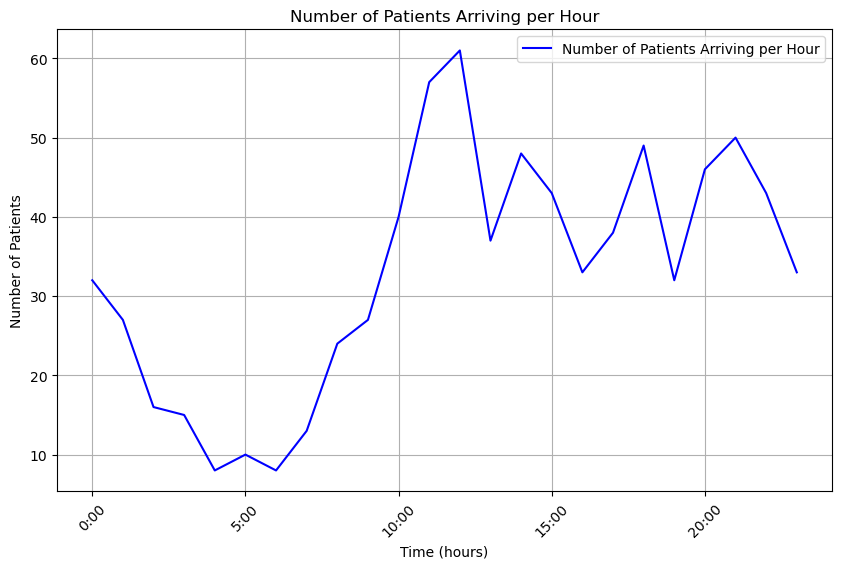

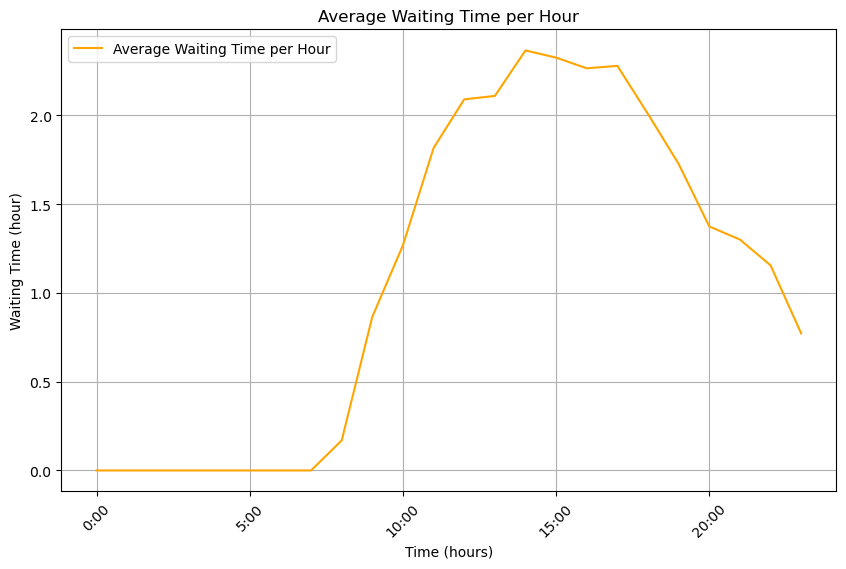

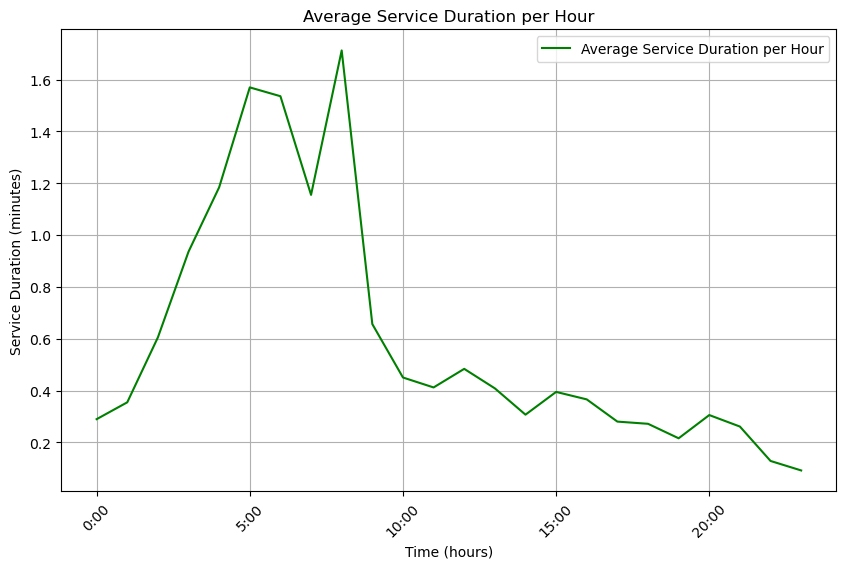

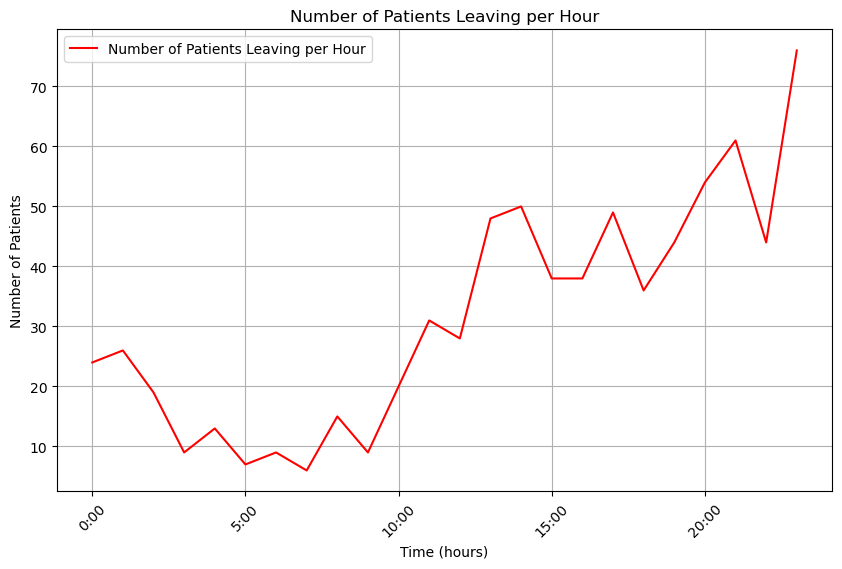

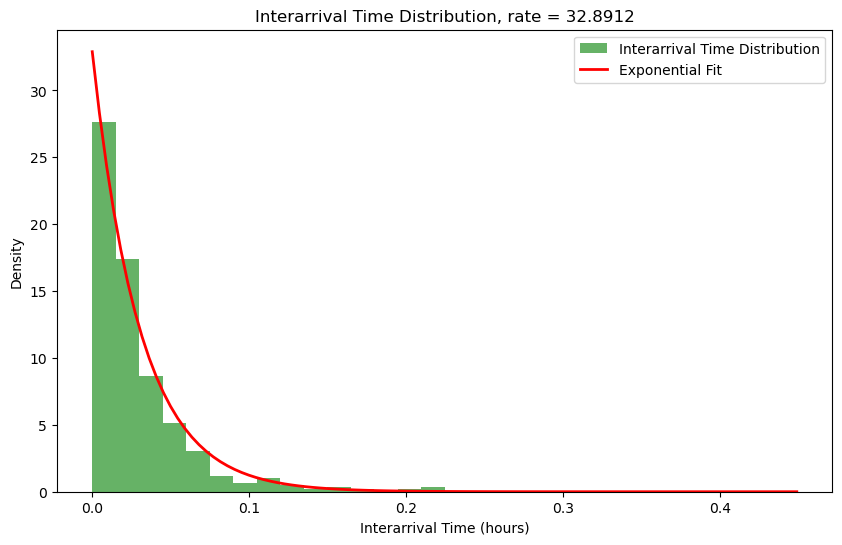

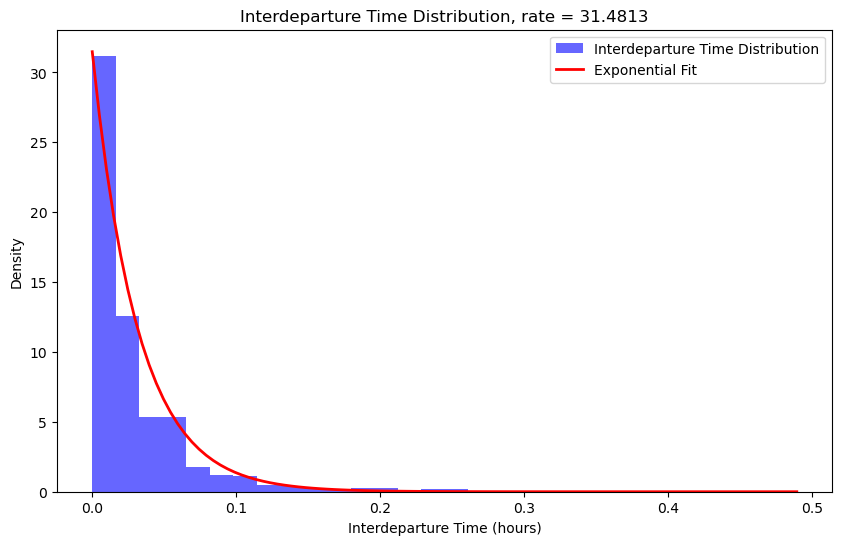

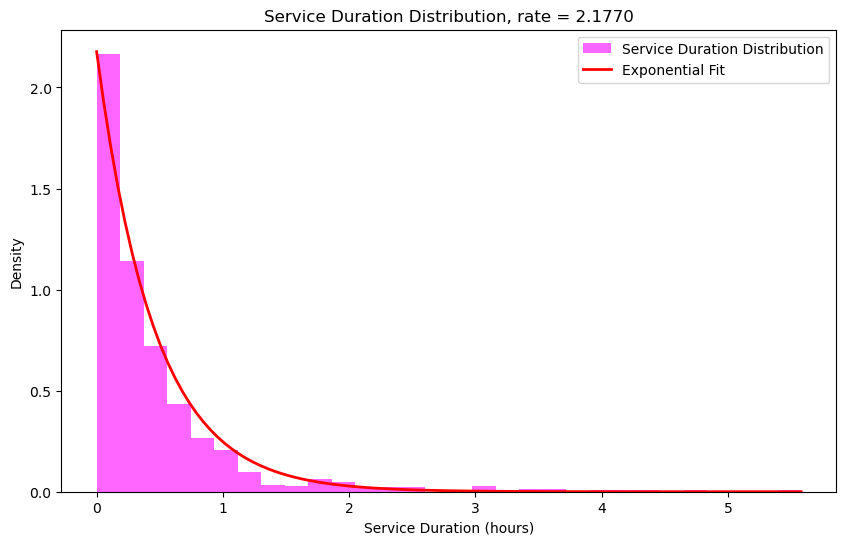

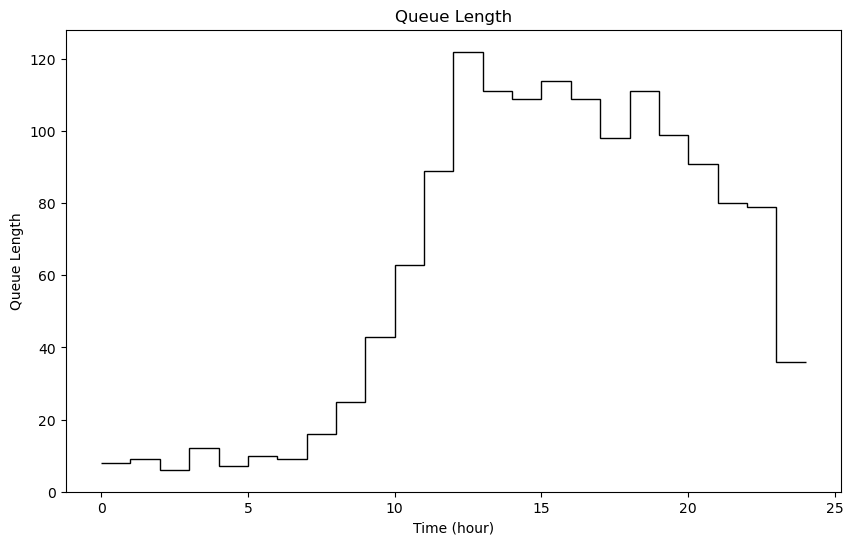

       Patient  Arrival Time  Waiting Time  Service Time  Service Duration  \
count  790.000       790.000       769.000       769.000           754.000   
mean   394.500        13.973         1.434        15.140             0.459   
std    228.198         6.394         0.829         6.793             0.636   
min      0.000         0.010         0.000         0.010             0.000   
25%    197.250        10.426         0.962        11.475             0.102   
50%    394.500        14.486         1.582        16.578             0.255   
75%    591.750        19.226         2.136        20.800             0.559   
max    789.000        23.998         2.453        23.985             5.579   

       Departure Time  
count         754.000  
mean           15.428  
std             6.595  
min             0.066  
25%            12.120  
50%            16.728  
75%            20.857  
max            23.985  


In [24]:
%time
# march 2024 averaged daily attendance for KCH (Total arrival was 27,404)
daily_average_arrivals = 805.1
#hourly_arrival = [daily_average_arrivals / 24 for _ in range(24)]
normalized_arrival_proportions = [p / sum(arrival_proportions) for p in arrival_proportions]
hourly_arrival = [daily_average_arrivals * p for p in arrival_proportions]

normalized_departure_proportions = [p / sum(departure_proportions) for p in departure_proportions]
hourly_departures = [daily_average_arrivals * p for p in departure_proportions]


shifts = {
        "morning": {"start": 8, "end": 16, "doctors": 19},
        "twilight": {"start": 16, "end": 24, "doctors": 15},
        "night": {"start": 0, "end": 8, "doctors": 11}
        }

def service_rate(hour, departure, shifts):
        for k in shifts:
               if shifts[k]["start"] <= hour < shifts[k]["end"]:
                       return departure/shifts[k]["doctors"]
        return

hourly_service = [service_rate(h,hourly_departures[h],shifts) for h in range(24)]

print(hourly_arrival)
print(hourly_departures)
print(hourly_service)
print(shifts)

sim_time = 24 # in hours
a_and_e = AandE(shifts, hourly_arrival, hourly_service)
a_and_e.run_simulation(simulation_time=sim_time)
a_and_e.doctors_per_hour()
a_and_e.save_log_to_csv('patient_log.csv')
a_and_e.visualize(simulation_time=sim_time)


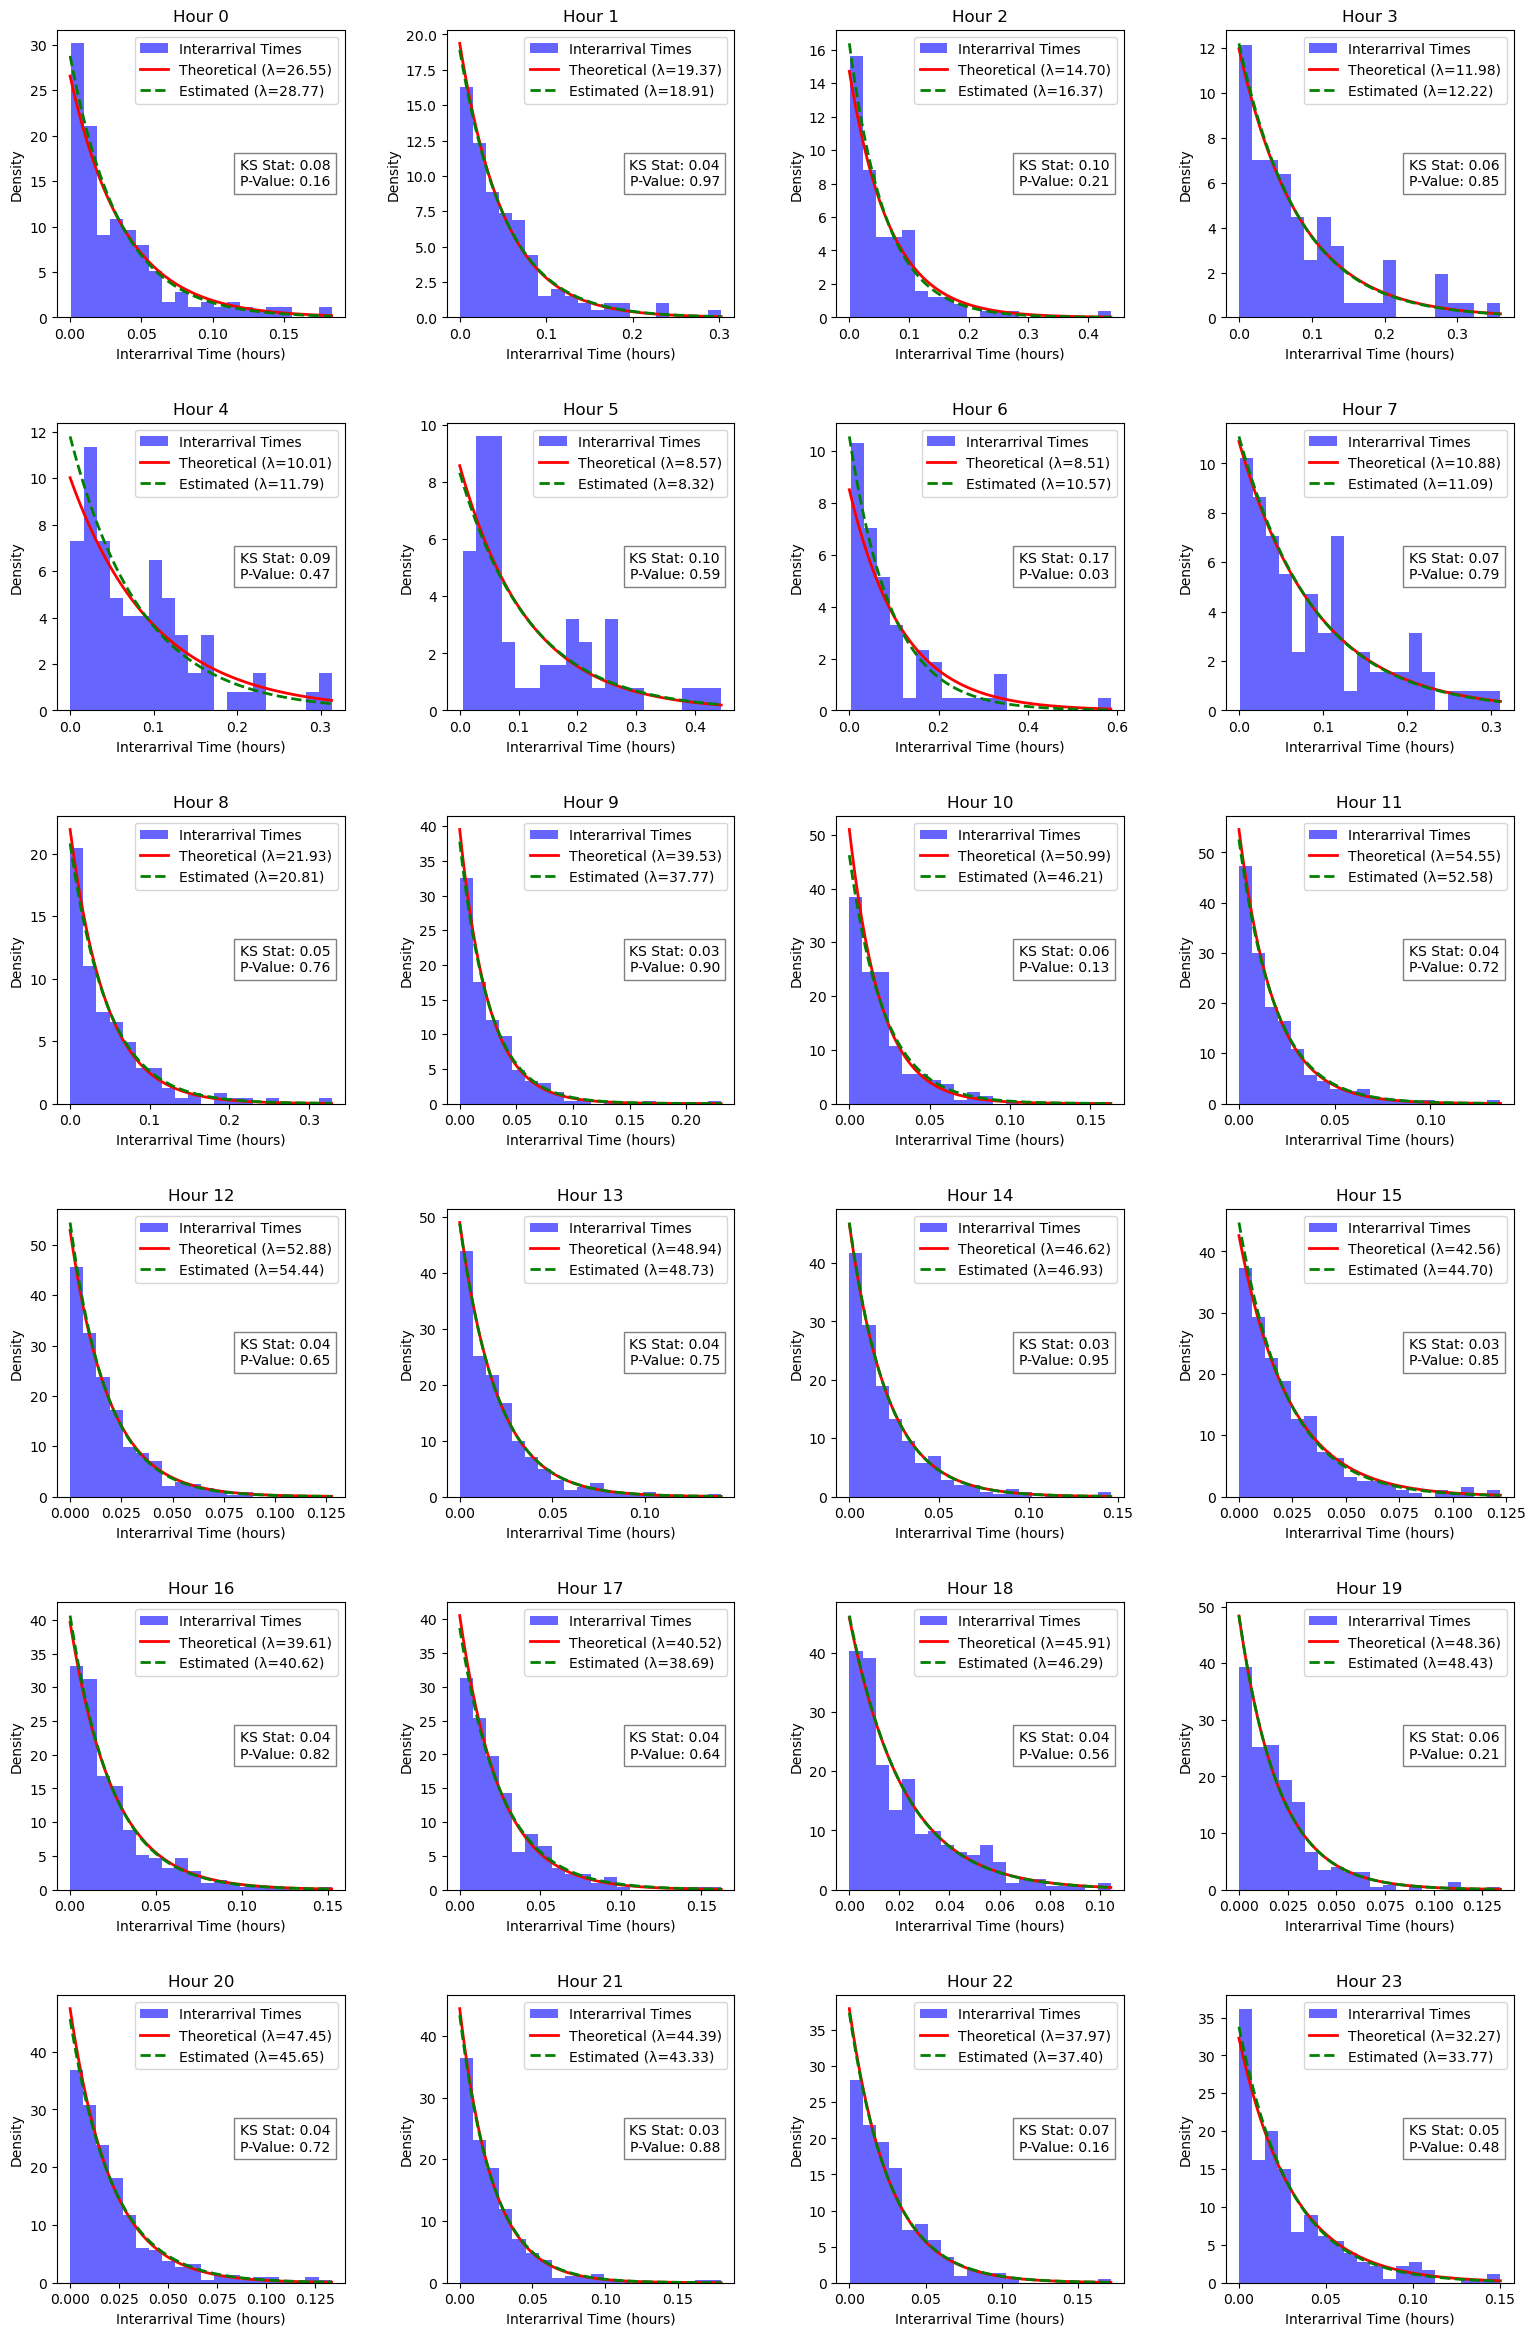

Summary Statistics for KS Statistics:
{'mean': 0.05903310295549905, 'std': 0.03127013970049784, 'min': 0.028363565367437893, 'max': 0.16998371179382432}

Summary Statistics for P-Values:
{'mean': 0.5933638580249213, 'std': 0.2876198697518272, 'min': 0.02588528035810156, 'max': 0.9664303716609884}


In [15]:
def validate_interarrival_times(patient_log, hourly_arrival_rates):

    if isinstance(patient_log, dict):
        patient_df = pd.DataFrame.from_dict(patient_log, orient='index')
    else:
        patient_df = patient_log

    interarrival_times = patient_df['Arrival Time'].sort_values().diff().dropna()

    # Plotting
    fig, axes = plt.subplots(6, 4, figsize=(16, 24))
    axes = axes.flatten()

    ks_statistics = []
    p_values = []

    for hour in range(24):
        # Get interarrival times for the current hour
        hourly_interarrivals = interarrival_times[
            patient_df['Arrival Time'].apply(lambda x: int(x % 24)) == hour
        ]

        ax = axes[hour]

        if len(hourly_interarrivals) > 0:
            lambda_input = hourly_arrival_rates[hour]
            lambda_estimate = 1 / hourly_interarrivals.mean()

            # Plot histogram and overlay exponential fit
            ax.hist(hourly_interarrivals, bins=20, density=True, alpha=0.6, color='blue', label='Interarrival Times')

            x = np.linspace(0, hourly_interarrivals.max(), 100)
            y_input = lambda_input * np.exp(-lambda_input * x)
            y_estimate = lambda_estimate * np.exp(-lambda_estimate * x)

            ax.plot(x, y_input, 'r-', lw=2, label=f'Theoretical (λ={lambda_input:.2f})')
            ax.plot(x, y_estimate, 'g--', lw=2, label=f'Estimated (λ={lambda_estimate:.2f})')

            ax.set_xlabel('Interarrival Time (hours)')
            ax.set_ylabel('Density')
            ax.set_title(f'Hour {hour}')
            ax.legend(loc='upper right')

            # Perform KS Test
            ks_statistic, p_value = stats.kstest(hourly_interarrivals, 'expon', args=(0, 1/lambda_input))
            ks_statistics.append(ks_statistic)
            p_values.append(p_value)

            # Annotate with statistics in the middle right
            stats_text = (
                f'KS Stat: {ks_statistic:.2f}\n'
                f'P-Value: {p_value:.2f}'
            )
            ax.text(0.95, 0.5, stats_text, transform=ax.transAxes, fontsize=10,
                    verticalalignment='center', horizontalalignment='right', bbox=dict(facecolor='white', alpha=0.5))

        else:
            ax.set_title(f'Hour {hour}')
            ax.text(0.5, 0.5, 'No data', transform=ax.transAxes,
                    horizontalalignment='center', verticalalignment='center')
            ax.set_xticks([])
            ax.set_yticks([])

    plt.tight_layout(pad=3.0)  # Adjust padding between plots for clarity
    plt.show()

    # Compute and print summary statistics for KS statistics and p-values
    ks_stat_summary = {
        'mean': np.mean(ks_statistics),
        'std': np.std(ks_statistics),
        'min': np.min(ks_statistics),
        'max': np.max(ks_statistics)
    }

    p_value_summary = {
        'mean': np.mean(p_values),
        'std': np.std(p_values),
        'min': np.min(p_values),
        'max': np.max(p_values)
    }

    print("Summary Statistics for KS Statistics:")
    print(ks_stat_summary)

    print("\nSummary Statistics for P-Values:")
    print(p_value_summary)

validate_interarrival_times(a_and_e.patient_log, hourly_arrival)
